# Лабораторная работа №1. Исследование алгоритма KNN (k ближайших соседей)

**Тематика:** машинное обучение на музыкальных данных.

| Задача | Датасет | Целевая переменная |
|---|---|---|
| Классификация | [GTZAN Music Genre Classification](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification) | жанр (10 классов) |
| Регрессия | [YearPredictionMSD](https://archive.ics.uci.edu/dataset/203/yearpredictionmsd) | год выпуска песни |

**План работы**
1. Выбор начальных условий: датасеты, их обоснование, метрики качества.
2. Бейзлайн: `KNeighborsClassifier` / `KNeighborsRegressor` из sklearn «из коробки».
3. Улучшение бейзлайна: гипотезы → проверка на кросс-валидации → улучшенный бейзлайн.
4. Собственная реализация KNN: сравнение с бейзлайном (п. 2) и с улучшенным бейзлайном (п. 3).
5. Итоги.

Импорты и общие настройки ноутбука

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, QuantileTransformer, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.data import RANDOM_STATE, download_data, gtzan_split, load_gtzan_raw, msd_split
from src.results import classification_metrics, regression_metrics, save_results

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
np.random.seed(RANDOM_STATE)

Скачиваем датасеты в data/, если их ещё нет (GTZAN — через kagglehub, MSD — с UCI)

In [2]:
download_data()

## 1. Выбор начальных условий

### 1.1. Классификация: GTZAN — определение жанра музыки

**Практическая задача.** Стриминговые сервисы (Яндекс Музыка, Spotify, Apple Music) и лейблы ежедневно получают
десятки тысяч новых треков. Ручная жанровая разметка дорога и субъективна, а жанр нужен для каталога,
поиска, тематических плейлистов и холодного старта рекомендательной системы (когда у трека ещё нет
прослушиваний). Модель, определяющая жанр по аудиосигналу, решает эту задачу автоматически.

**Данные.** GTZAN — классический бенчмарк для распознавания жанров: 1000 треков по 30 секунд, 10 жанров по 100 треков.
Используется файл `features_3_sec.csv`: каждый трек нарезан на 10 фрагментов по 3 секунды, для каждого
посчитаны 57 признаков (библиотека librosa):
* `chroma_stft` — распределение энергии по 12 нотам (гармония/тональность);
* `rms` — громкость; `zero_crossing_rate` — «шумность»/перкуссивность;
* `spectral_centroid`, `spectral_bandwidth`, `rolloff` — «яркость» и ширина спектра;
* `harmony`, `perceptr` — гармоническая и перкуссионная составляющие; `tempo` — темп (BPM);
* `mfcc1..20` — мел-кепстральные коэффициенты, описывающие тембр.

Для каждого признака (кроме темпа) есть среднее (`_mean`) и дисперсия (`_var`) по фрагменту.

**Почему подходит для KNN и последующих ЛР:** все признаки числовые, пропусков нет, классы сбалансированы,
размер (~10 тыс. объектов) позволяет обучать как простые, так и ансамблевые модели.

Загружаем сырой GTZAN и смотрим на структуру

In [3]:
gtzan = load_gtzan_raw()
print("Размер:", gtzan.shape, "| треков:", gtzan["track"].nunique(), "| пропусков:", gtzan.isna().sum().sum())
gtzan.head()

Размер: (9990, 61) | треков: 1000 | пропусков: 0


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label,track
0,blues.00000.0.wav,66149,0.3354,0.0910,0.1304,0.0035,1773.0650,167541.6309,1972.7444,117335.7716,...,-3.2413,36.4882,0.7222,38.0992,-5.0503,33.6181,-0.2430,43.7718,blues,blues.00000
1,blues.00000.1.wav,66149,0.3431,0.0861,0.1127,0.0014,1816.6938,90525.6909,2010.0515,65671.8757,...,-6.0553,40.6777,0.1590,51.2641,-2.8377,97.0308,5.7841,59.9431,blues,blues.00000
2,blues.00000.2.wav,66149,0.3468,0.0922,0.1320,0.0046,1788.5397,111407.4376,2084.5651,75124.9217,...,-1.7686,28.3486,2.3788,45.7176,-1.9384,53.0508,2.5174,33.1051,blues,blues.00000
3,blues.00000.3.wav,66149,0.3636,0.0869,0.1326,0.0024,1655.2890,111952.2845,1960.0400,82913.6393,...,-3.8412,28.3371,1.2186,34.7709,-3.5804,50.8362,3.6309,32.0237,blues,blues.00000
4,blues.00000.4.wav,66149,0.3356,0.0881,0.1433,0.0017,1630.6562,79667.2677,1948.5039,60204.0203,...,0.6646,45.8809,1.6894,51.3636,-3.3925,26.7388,0.5370,29.1467,blues,blues.00000


Баланс классов: количество фрагментов каждого жанра

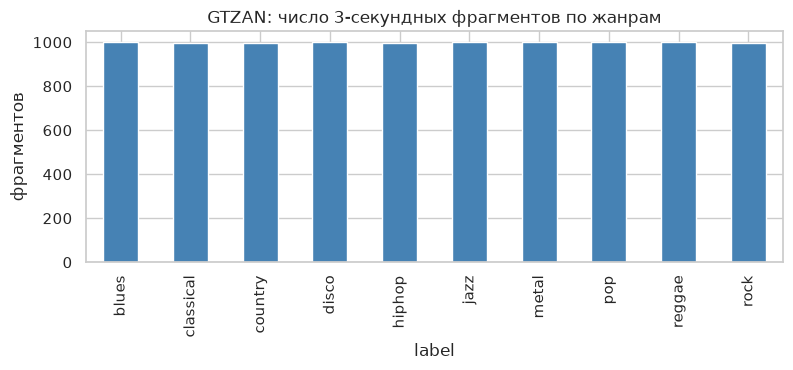

In [4]:
ax = gtzan["label"].value_counts().sort_index().plot.bar(figsize=(9, 3), color="steelblue")
ax.set_title("GTZAN: число 3-секундных фрагментов по жанрам"); ax.set_ylabel("фрагментов")
plt.show()

Как отличаются жанры по нескольким интерпретируемым признакам

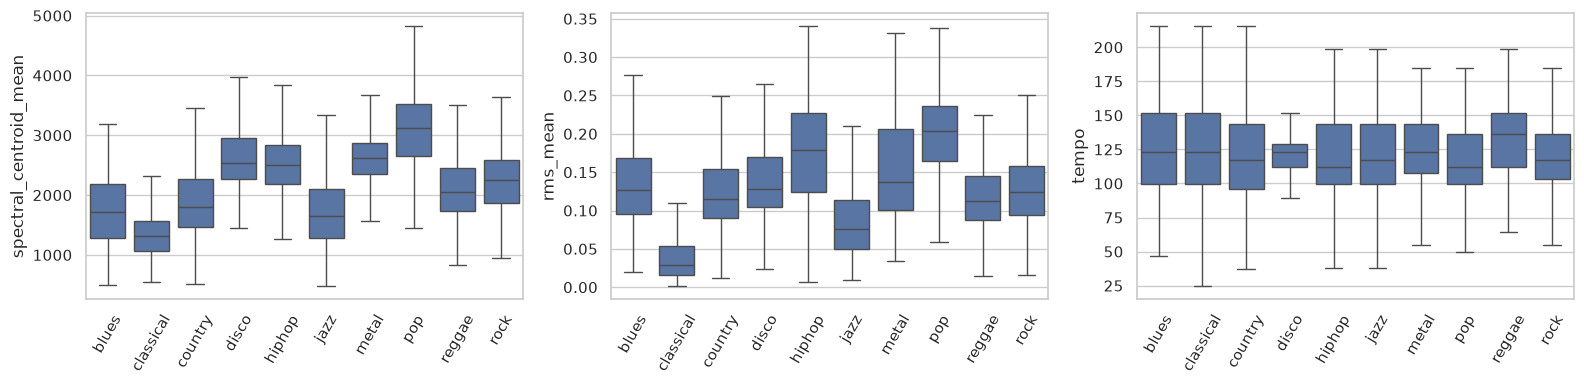

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["spectral_centroid_mean", "rms_mean", "tempo"]):
    sns.boxplot(data=gtzan, x="label", y=col, ax=ax, showfliers=False)
    ax.tick_params(axis="x", rotation=60); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Видно, что признаки действительно несут информацию о жанре: классическая музыка тихая и «тёмная»
(низкий спектральный центроид), метал и поп — громкие и «яркие». Темп разделяет жанры слабо.

**Важная особенность данных — утечка через фрагменты.** 10 фрагментов одного трека очень похожи друг на друга.
Если разбивать данные на train/test случайно по строкам, то для фрагмента из теста в обучающей выборке почти
всегда найдётся «сосед» из того же трека, и KNN будет угадывать жанр, по сути, узнавая песню. Поэтому
разбиение делается **по трекам** (`GroupShuffleSplit`, 80/20), а кросс-валидация — `GroupKFold`.
Насколько сильно влияет утечка, проверим в п. 3.

Фиксированное разбиение по трекам, общее для всех ЛР (см. src/data.py)

In [6]:
Xc_train, Xc_test, yc_train, yc_test, gc_train, gc_test = gtzan_split()
print("train:", Xc_train.shape, "test:", Xc_test.shape)
print("Общих треков в train и test:", len(set(gc_train) & set(gc_test)))

train: (7993, 57) test: (1997, 57)
Общих треков в train и test: 0


### 1.2. Регрессия: YearPredictionMSD — предсказание года выпуска песни

**Практическая задача.** В музыкальных каталогах у огромного числа записей отсутствует или указан неверно год
выпуска (переиздания, сборники, оцифрованные архивы, пользовательские загрузки). Год (точнее, «эпоха звучания»)
нужен для плейлистов по десятилетиям («Хиты 80-х»), рекомендаций, поиска и проверки метаданных.
Модель, оценивающая год по звучанию трека, позволяет заполнять и валидировать такие метаданные.

**Данные.** Подмножество Million Song Dataset (UCI, 515 345 песен 1922–2011 гг.). Признаки — 90 характеристик
тембра от Echo Nest: 12 средних значений тембральных коэффициентов по сегментам песни и 78 элементов их
ковариационной матрицы. Целевая переменная — год выпуска.

**Разбиение.** Используется официальное разбиение UCI (первые 463 715 строк — train, остальные — test):
оно гарантирует, что песни одного исполнителя не попадают и в train, и в test (иначе модель «узнавала» бы
исполнителя). Из каждой части берётся случайная подвыборка: **50 000 train / 10 000 test**. Это нужно, чтобы
полный перебор соседей в собственной реализации KNN и подбор гиперпараметров на кросс-валидации выполнялись
за разумное время. Подвыборка фиксирована и одинакова для всех ЛР.

Загружаем фиксированную подвыборку MSD

In [7]:
Xr_train, Xr_test, yr_train, yr_test = msd_split()
print("train:", Xr_train.shape, "test:", Xr_test.shape)
Xr_train.iloc[:5, :8]

train: (50000, 90) test: (10000, 90)


,timbre_avg_1,timbre_avg_2,timbre_avg_3,timbre_avg_4,timbre_avg_5,timbre_avg_6,timbre_avg_7,timbre_avg_8
0,51.1959,18.5408,12.5520,3.2500,-7.7954,-19.6346,0.2766,-1.0399
1,51.4457,53.4262,35.8348,-16.7287,-48.1319,-13.0425,-45.7408,-6.1879
2,44.8521,33.5105,27.4463,24.9978,-15.0251,12.2922,10.5737,7.0641
3,50.2565,59.8324,37.8021,-0.5776,-1.6406,-11.7788,-2.2557,-4.1701
4,45.4878,-5.4979,9.5619,9.3698,-11.1573,-3.6334,11.0030,-6.3672


Распределение целевой переменной: годы выпуска в train и test

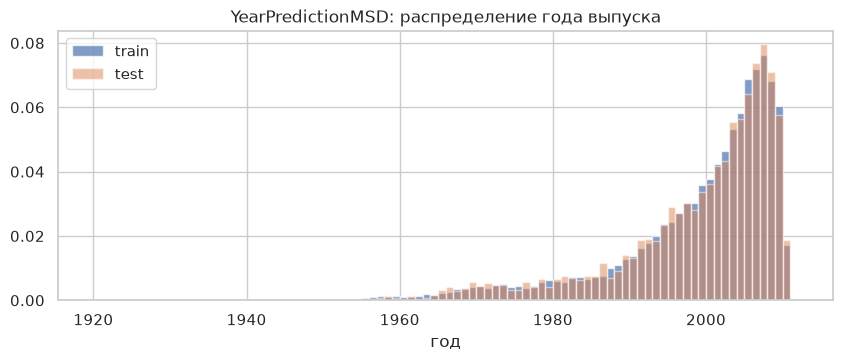

count    50000.0000
mean      1998.4291
std         10.9060
min       1926.0000
25%       1994.0000
50%       2002.0000
75%       2006.0000
max       2010.0000
dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(yr_train, bins=np.arange(1920, 2013), alpha=.7, label="train", density=True)
ax.hist(yr_test, bins=np.arange(1920, 2013), alpha=.5, label="test", density=True)
ax.set_title("YearPredictionMSD: распределение года выпуска"); ax.set_xlabel("год"); ax.legend()
plt.show()
print(pd.Series(yr_train).describe())

Масштабы признаков сильно различаются — это критично для метрических методов вроде KNN

In [9]:
Xr_train.describe().T[["mean", "std", "min", "max"]].sort_values("std", ascending=False).head(8)

,mean,std,min,max
timbre_cov_2,2442.7930,1743.8976,75.6756,47953.1133
timbre_cov_3,1975.9286,1265.5795,62.1297,28231.0996
timbre_cov_4,1514.1875,1074.0372,58.1021,25511.3281
timbre_cov_14,39.3151,707.5941,-11568.5059,16337.8672
timbre_cov_6,880.6076,572.7577,33.3837,12085.8652
timbre_cov_15,-50.2382,546.9197,-8374.3203,14505.3418
timbre_cov_5,915.2726,487.7551,29.3691,15922.6494
timbre_cov_35,80.4538,470.9003,-10676.6416,9059.7598


Распределение года сильно смещено влево: большинство песен вышли после 1990 года, ранних записей мало.
Значит, постоянный прогноз «около 2000 года» уже даёт небольшую ошибку, и модель нужно сравнивать с ним.
Масштабы признаков различаются на порядки (стандартное отклонение от единиц до тысяч), поэтому без
нормализации расстояние в KNN будет определяться лишь несколькими признаками.

### 1.3. Выбор метрик качества

**Классификация (GTZAN):**
* **macro-F1 — основная метрика.** Это среднее F1 по жанрам: каждый жанр вносит одинаковый вклад, а сама
  метрика учитывает и точность (не приписываем трекам чужой жанр), и полноту (находим все треки жанра).
  Для каталога важны все жанры, а не только самые лёгкие.
* **accuracy** — доля верно определённых жанров. Классы сбалансированы, поэтому accuracy корректна и легко
  интерпретируется («модель угадывает жанр в X % случаев»). Случайное угадывание даёт ≈ 0.10.

**Регрессия (MSD):**
* **MAE — основная метрика.** Средняя абсолютная ошибка в годах, напрямую интерпретируемая
  («в среднем ошибаемся на N лет»). Она устойчива к выбросам — редким очень старым записям.
* **RMSE** сильнее штрафует большие ошибки (например, когда запись 1950-х приняли за 2000-е).
* **R²** показывает долю объяснённой дисперсии, то есть насколько модель лучше константного прогноза
  (R² = 0 соответствует константе).

Для ориентира посчитаем «нулевые» модели: самый частый класс и средний год.

Нулевые модели: нижняя граница качества, ниже которой модель бесполезна

In [10]:
dummy_c = DummyClassifier(strategy="most_frequent").fit(Xc_train, yc_train)
dummy_r = DummyRegressor(strategy="mean").fit(Xr_train, yr_train)
pd.DataFrame({"GTZAN (most_frequent)": classification_metrics(yc_test, dummy_c.predict(Xc_test)),
              "MSD (mean)": regression_metrics(yr_test, dummy_r.predict(Xr_test))}).T

,accuracy,f1_macro,MAE,RMSE,R2
GTZAN (most_frequent),0.0651,0.0122,NaN,NaN,NaN
MSD (mean),NaN,NaN,8.1748,10.8879,-4.7542e-06


## 2. Создание бейзлайна и оценка качества

Бейзлайн — модели sklearn с параметрами по умолчанию (`n_neighbors=5`, евклидово расстояние, равные веса
соседей) на исходных признаках без какой-либо предобработки.

Словарь для всех результатов ЛР: {задача: {вариант: метрики}}

In [11]:
results = {"classification": {}, "regression": {}}

t0 = time.time()
base_clf = KNeighborsClassifier().fit(Xc_train, yc_train)
results["classification"]["sklearn baseline"] = classification_metrics(yc_test, base_clf.predict(Xc_test))
print(f"Классификация: {time.time() - t0:.1f} c")

t0 = time.time()
base_reg = KNeighborsRegressor().fit(Xr_train, yr_train)
results["regression"]["sklearn baseline"] = regression_metrics(yr_test, base_reg.predict(Xr_test))
print(f"Регрессия: {time.time() - t0:.1f} c")

pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

Классификация: 0.0 c


Регрессия: 0.7 c


(                  accuracy  f1_macro
 sklearn baseline    0.2278    0.2347,
                      MAE     RMSE      R2
 sklearn baseline  8.0154  10.9928 -0.0194)

**Выводы по бейзлайну.**
* Классификация: качество ~0.23 лишь в ~2 раза выше случайного угадывания (0.10). Причина — признаки в разных
  масштабах: дисперсии спектральных характеристик (порядка 10⁵–10⁶) полностью определяют евклидово расстояние,
  а информативные MFCC фактически не учитываются.
* Регрессия: MAE почти такой же, как у константного прогноза, а R² отрицательный, то есть модель хуже среднего.
  Причины те же: признаки в разных масштабах и слишком мало соседей (k = 5) для зашумлённой задачи.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

| № | Гипотеза | Задача |
|---|---|---|
| Г1 | Случайное разбиение по строкам даёт утечку данных и завышает оценку, поэтому разбивать нужно по трекам | классиф. |
| Г2 | Стандартизация признаков (`StandardScaler`) значительно улучшит качество, так как KNN чувствителен к масштабу | обе |
| Г3 | У признаков-дисперсий (`*_var`) и ковариаций тяжёлые хвосты. Преобразования к нормальному виду (`PowerTransformer`, `QuantileTransformer`) уменьшат влияние выбросов на расстояние | обе |
| Г4 | Снижение размерности (PCA) или отбор признаков уберёт шум и коррелированные признаки | обе |
| Г5 | Подбор гиперпараметров на кросс-валидации (`k`, взвешивание соседей, метрика расстояния) | обе |

Все гипотезы проверяются **только на кросс-валидации по обучающей выборке**: тестовая выборка используется
один раз — для финальной оценки улучшенного бейзлайна. Для GTZAN используется `GroupKFold` по трекам
(5 фолдов), для MSD — `KFold` (5 фолдов).

Вспомогательные функции для оценки гипотез на кросс-валидации

In [12]:
cv_c = GroupKFold(n_splits=5)
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_clf(model, X=Xc_train, cv=cv_c, groups=gc_train):
    return cross_val_score(model, X, yc_train, cv=cv, groups=groups, scoring="f1_macro", n_jobs=5).mean()

def cv_reg(model, X=Xr_train):
    return -cross_val_score(model, X, yr_train, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=5).mean()

hyp_c, hyp_r = {}, {}
hyp_c["бейзлайн (сырые признаки)"] = cv_clf(KNeighborsClassifier())
hyp_r["бейзлайн (сырые признаки)"] = cv_reg(KNeighborsRegressor())

#### Г1. Утечка данных через фрагменты одного трека (классификация)

Сравниваем кросс-валидацию без учёта групп (StratifiedKFold) и с учётом треков (GroupKFold)

In [13]:
scaled_knn = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
leaky = cv_clf(scaled_knn, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), groups=None)
honest = cv_clf(scaled_knn)
print(f"macro-F1, случайные фолды (утечка): {leaky:.3f}")
print(f"macro-F1, фолды по трекам (честно):  {honest:.3f}")

macro-F1, случайные фолды (утечка): 0.887
macro-F1, фолды по трекам (честно):  0.657


**Г1 подтверждена.** При случайном разбиении оценка завышена примерно на 23 п.п. (0.89 против 0.66): модель «узнаёт» трек по соседним
фрагментам. Дальше везде используется разбиение по трекам. Эта гипотеза не меняет модель, но
делает все остальные оценки корректными.

#### Г2. Стандартизация признаков

KNN + StandardScaler внутри Pipeline (скейлер обучается только на train-части каждого фолда)

In [14]:
hyp_c["Г2: StandardScaler"] = cv_clf(Pipeline([("prep", StandardScaler()), ("knn", KNeighborsClassifier())]))
hyp_r["Г2: StandardScaler"] = cv_reg(Pipeline([("prep", StandardScaler()), ("knn", KNeighborsRegressor())]))
print(f"GTZAN macro-F1: {hyp_c['бейзлайн (сырые признаки)']:.3f} -> {hyp_c['Г2: StandardScaler']:.3f}")
print(f"MSD   MAE:      {hyp_r['бейзлайн (сырые признаки)']:.3f} -> {hyp_r['Г2: StandardScaler']:.3f}")

GTZAN macro-F1: 0.250 -> 0.657
MSD   MAE:      8.118 -> 7.321


**Г2 подтверждена** для обеих задач: это самое сильное улучшение. На GTZAN macro-F1 вырос почти в 3 раза,
на MSD ошибка заметно уменьшилась. Без масштабирования KNN использовать нельзя.

#### Г3. Преобразования распределений признаков

Смотрим на распределения нескольких признаков до и после PowerTransformer (Yeo-Johnson)

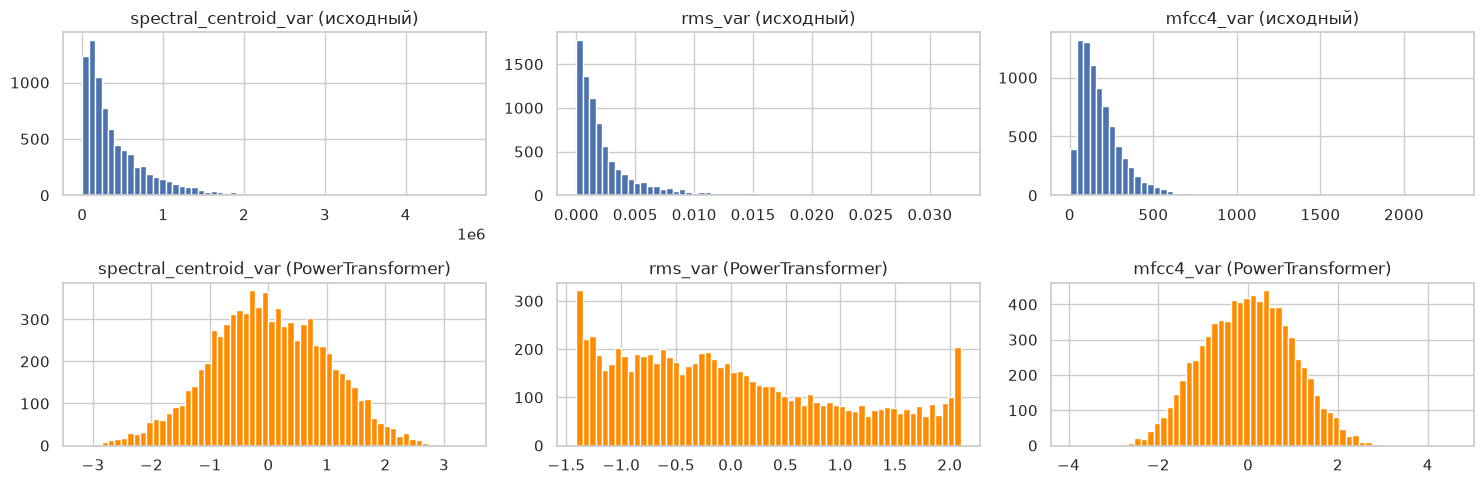

Коэф. асимметрии GTZAN (медиана по признакам): 0.68
Коэф. асимметрии MSD (медиана по признакам):   0.17


In [15]:
cols = ["spectral_centroid_var", "rms_var", "mfcc4_var"]
pt_demo = PowerTransformer().fit(Xc_train[cols])
fig, axes = plt.subplots(2, 3, figsize=(15, 5))
for i, col in enumerate(cols):
    axes[0, i].hist(Xc_train[col], bins=60); axes[0, i].set_title(f"{col} (исходный)")
    axes[1, i].hist(pt_demo.transform(Xc_train[cols])[:, i], bins=60, color="darkorange")
    axes[1, i].set_title(f"{col} (PowerTransformer)")
plt.tight_layout(); plt.show()
print("Коэф. асимметрии GTZAN (медиана по признакам):", round(Xc_train.skew().median(), 2))
print("Коэф. асимметрии MSD (медиана по признакам):  ", round(Xr_train.skew().median(), 2))

Сравниваем преобразования: Yeo-Johnson (PowerTransformer) и квантильное к нормальному распределению

In [16]:
for name, prep in [("PowerTransformer", PowerTransformer()),
                   ("QuantileTransformer", QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE))]:
    hyp_c[f"Г3: {name}"] = cv_clf(Pipeline([("prep", prep), ("knn", KNeighborsClassifier())]))
    hyp_r[f"Г3: {name}"] = cv_reg(Pipeline([("prep", clone(prep)), ("knn", KNeighborsRegressor())]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн (сырые признаки),0.2502,8.1182
Г2: StandardScaler,0.6574,7.3210
Г3: PowerTransformer,0.6703,7.3084
Г3: QuantileTransformer,0.6764,7.4116


**Г3 подтверждена для GTZAN.** Признаки-дисперсии имеют сильно скошенные распределения с длинными хвостами.
После преобразования выбросы перестают доминировать в расстоянии, и macro-F1 растёт относительно простой
стандартизации.
**Для MSD Г3 не подтвердилась:** преобразования дают результат на уровне стандартизации (или хуже).
Признаки MSD — средние и ковариации тембра по всей песне, их распределения ближе к нормальному.

#### Г4. Снижение размерности (PCA) и отбор признаков

PCA после лучшей предобработки; для MSD дополнительно пробуем только 12 средних тембра (без ковариаций)

In [17]:
for n in [10, 20, 40]:
    hyp_c[f"Г4: Power + PCA({n})"] = cv_clf(Pipeline([("prep", PowerTransformer()), ("pca", PCA(n, random_state=RANDOM_STATE)),
                                                     ("knn", KNeighborsClassifier())]))
    hyp_r[f"Г4: Scaler + PCA({n})"] = cv_reg(Pipeline([("prep", StandardScaler()), ("pca", PCA(n, random_state=RANDOM_STATE)),
                                                      ("knn", KNeighborsRegressor())]))
hyp_r["Г4: только 12 средних тембра"] = cv_reg(Pipeline([("prep", StandardScaler()), ("knn", KNeighborsRegressor())]),
                                               X=Xr_train.iloc[:, :12])
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн (сырые признаки),0.2502,8.1182
Г2: StandardScaler,0.6574,7.3210
Г3: PowerTransformer,0.6703,7.3084
Г3: QuantileTransformer,0.6764,7.4116
Г4: Power + PCA(10),0.5993,NaN
Г4: Power + PCA(20),0.6333,NaN
Г4: Power + PCA(40),0.6584,NaN
Г4: Scaler + PCA(10),NaN,8.1522
Г4: Scaler + PCA(20),NaN,7.7368
Г4: Scaler + PCA(40),NaN,7.5840


**Г4 не подтвердилась.** PCA ухудшает качество в обеих задачах: главные компоненты выбираются по дисперсии, а не по
связи с целевой переменной, поэтому вместе с шумом теряется полезная информация. Для MSD отказ от ковариаций
тембра тоже ухудшает результат: они несут информацию о годе. Снижение размерности в улучшенный бейзлайн
не включаем.

#### Г5. Подбор гиперпараметров на кросс-валидации

Перебираем по сетке (`GridSearchCV`):
* `n_neighbors` — число соседей: малое k даёт переобучение на шум, большое — слишком «гладкую» модель;
* `weights` — равные веса соседей или веса, обратно пропорциональные расстоянию;
* `metric` — евклидово, манхэттенское или косинусное расстояние;
* для GTZAN также тип предобработки (StandardScaler / PowerTransformer / QuantileTransformer) — варианты из Г2–Г3.

Сетка для классификации (GroupKFold по трекам, оптимизируем macro-F1)

In [18]:
pipe_c = Pipeline([("prep", StandardScaler()), ("knn", KNeighborsClassifier())])
grid_c = GridSearchCV(pipe_c, {
    "prep": [StandardScaler(), PowerTransformer(),
             QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE)],
    "knn__n_neighbors": [1, 3, 5, 7, 10, 15, 20, 30, 50],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "cosine"],
}, cv=cv_c, scoring="f1_macro", n_jobs=6)
t0 = time.time(); grid_c.fit(Xc_train, yc_train, groups=gc_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_c.best_params_} | CV macro-F1 = {grid_c.best_score_:.4f}")
hyp_c["Г5: GridSearchCV"] = grid_c.best_score_

110 c | лучшие параметры: {'knn__metric': 'manhattan', 'knn__n_neighbors': 10, 'knn__weights': 'distance', 'prep': QuantileTransformer(output_distribution='normal', random_state=42)} | CV macro-F1 = 0.7016


Сетка для регрессии (KFold, оптимизируем MAE); предобработка — StandardScaler по итогам Г2–Г3

In [19]:
pipe_r = Pipeline([("prep", StandardScaler()), ("knn", KNeighborsRegressor())])
grid_r = GridSearchCV(pipe_r, {
    "knn__n_neighbors": [5, 10, 20, 30, 50, 75, 100, 150],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "cosine"],
}, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=6)
t0 = time.time(); grid_r.fit(Xr_train, yr_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_r.best_params_} | CV MAE = {-grid_r.best_score_:.4f}")
hyp_r["Г5: GridSearchCV"] = -grid_r.best_score_

507 c | лучшие параметры: {'knn__metric': 'cosine', 'knn__n_neighbors': 30, 'knn__weights': 'distance'} | CV MAE = 6.8645


Как качество зависит от k для разных метрик (взвешивание — как у лучшей модели)

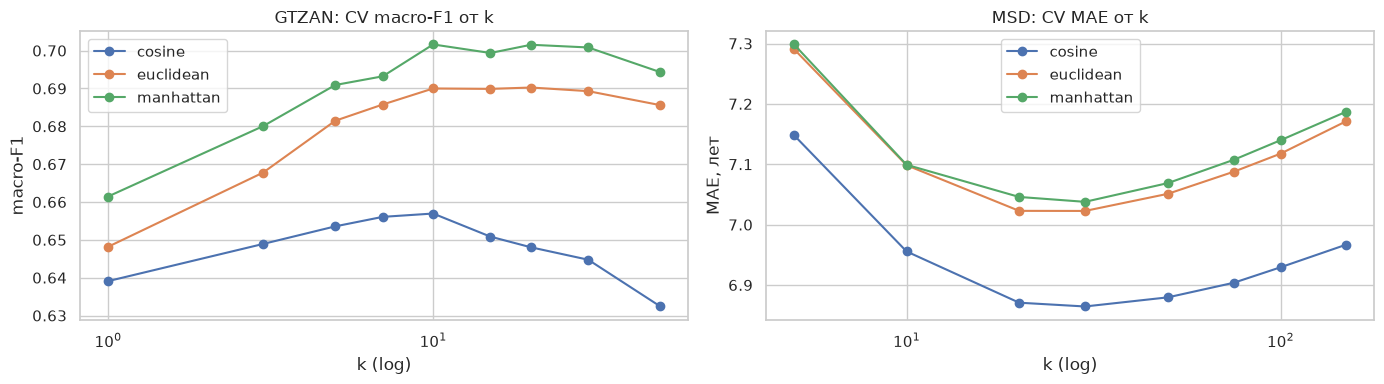

In [20]:
def plot_k(grid, title, ylabel, sign=1, extra=None):
    cv = pd.DataFrame(grid.cv_results_)
    w = grid.best_params_["knn__weights"]
    cv = cv[cv["param_knn__weights"] == w]
    if extra:
        cv = cv[cv["param_prep"].astype(str) == str(grid.best_params_["prep"])]
    for metric, part in cv.groupby("param_knn__metric"):
        plt.plot(part["param_knn__n_neighbors"], sign * part["mean_test_score"], marker="o", label=metric)
    plt.xscale("log"); plt.xlabel("k (log)"); plt.ylabel(ylabel); plt.title(title); plt.legend()

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1); plot_k(grid_c, "GTZAN: CV macro-F1 от k", "macro-F1", extra=True)
plt.subplot(1, 2, 2); plot_k(grid_r, "MSD: CV MAE от k", "MAE, лет", sign=-1)
plt.tight_layout(); plt.show()

**Г5 подтверждена.**
* GTZAN: лучше всего работает манхэттенское расстояние с весами по расстоянию и QuantileTransformer.
  L1-метрика менее чувствительна к большим отклонениям по отдельным признакам, а взвешивание даёт ближайшим
  соседям (часто фрагментам похожих по звучанию треков) больший голос.
* MSD: оптимальное k намного больше, чем 5. Задача сильно зашумлена: похожий тембр бывает у песен разных лет,
  поэтому нужно усреднять по многим соседям. Косинусное расстояние учитывает «форму» тембрального профиля,
  а не его абсолютную величину, и работает лучше евклидова.

Сводка проверки всех гипотез на кросс-валидации

In [21]:
summary = pd.concat([pd.Series(hyp_c, name="GTZAN CV macro-F1 ↑"), pd.Series(hyp_r, name="MSD CV MAE ↓")], axis=1)
summary

,GTZAN CV macro-F1 ↑,MSD CV MAE ↓
бейзлайн (сырые признаки),0.2502,8.1182
Г2: StandardScaler,0.6574,7.3210
Г3: PowerTransformer,0.6703,7.3084
Г3: QuantileTransformer,0.6764,7.4116
Г4: Power + PCA(10),0.5993,NaN
Г4: Power + PCA(20),0.6333,NaN
Г4: Power + PCA(40),0.6584,NaN
Г5: GridSearchCV,0.7016,6.8645
Г4: Scaler + PCA(10),NaN,8.1522
Г4: Scaler + PCA(20),NaN,7.7368


### 3.2. Улучшенный бейзлайн

По итогам проверки гипотез улучшенный бейзлайн включает:
* **классификация:** разбиение по трекам (Г1) + QuantileTransformer (Г3) + KNN с подобранными на CV `k`,
  весами и метрикой (Г5);
* **регрессия:** StandardScaler (Г2) + KNN с подобранными на CV `k`, весами и метрикой (Г5).

Обучаем на всей обучающей выборке и один раз оцениваем на тесте.

Обучаем улучшенные модели на полном train (GridSearchCV уже сделал refit) и оцениваем на test

In [22]:
best_clf, best_reg = grid_c.best_estimator_, grid_r.best_estimator_
yc_pred_best = best_clf.predict(Xc_test)
yr_pred_best = best_reg.predict(Xr_test)
results["classification"]["sklearn improved"] = classification_metrics(yc_test, yc_pred_best)
results["regression"]["sklearn improved"] = regression_metrics(yr_test, yr_pred_best)
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

(                  accuracy  f1_macro
 sklearn baseline    0.2278    0.2347
 sklearn improved    0.6765    0.6828,
                      MAE     RMSE      R2
 sklearn baseline  8.0154  10.9928 -0.0194
 sklearn improved  7.0208   9.8566  0.1805)

Матрица ошибок улучшенного классификатора и «прогноз vs факт» для регрессии

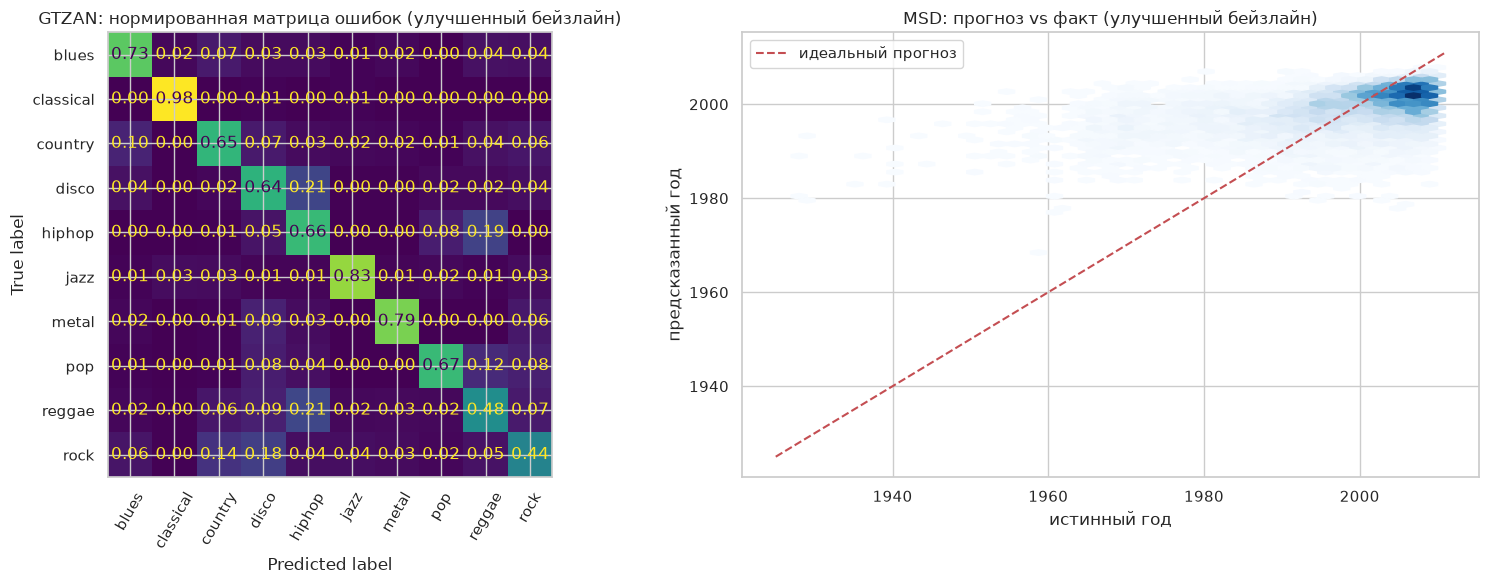

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_best, normalize="true", values_format=".2f",
                                        ax=axes[0], colorbar=False, xticks_rotation=60)
axes[0].set_title("GTZAN: нормированная матрица ошибок (улучшенный бейзлайн)")
axes[1].hexbin(yr_test, yr_pred_best, gridsize=40, cmap="Blues", mincnt=1)
axes[1].plot([1925, 2011], [1925, 2011], "r--", label="идеальный прогноз")
axes[1].set_xlabel("истинный год"); axes[1].set_ylabel("предсказанный год"); axes[1].legend()
axes[1].set_title("MSD: прогноз vs факт (улучшенный бейзлайн)")
plt.tight_layout(); plt.show()

Дополнительно: точность на уровне целого трека (голосование 10 фрагментов) — так модель использовалась бы на практике

In [24]:
track_votes = pd.DataFrame({"track": gc_test, "pred": yc_pred_best, "true": yc_test}).groupby("track").agg(
    pred=("pred", lambda s: s.mode()[0]), true=("true", "first"))
print(f"Accuracy по фрагментам: {results['classification']['sklearn improved']['accuracy']:.3f}")
print(f"Accuracy по трекам (голосование): {(track_votes.pred == track_votes.true).mean():.3f}")

Accuracy по фрагментам: 0.677
Accuracy по трекам (голосование): 0.740


**Выводы по улучшенному бейзлайну (сравнение с п. 2).**
* **Классификация:** macro-F1 и accuracy выросли примерно в 3 раза по сравнению с бейзлайном. Лучше всего
  распознаются classical, jazz и metal (F1 ≈ 0.84–0.95). Хуже всего — rock, reggae и hiphop (F1 ≈ 0.5), а также
  disco. Эти жанры путаются между собой и с country/blues: у них близкие тембр и инструменты, и на уровне
  3-секундных фрагментов они звучат похоже. Если агрегировать предсказания
  10 фрагментов голосованием, точность на уровне трека становится ещё выше. Так модель и применялась бы на практике.
* **Регрессия:** MAE снизился, R² стал положительным: модель объясняет часть дисперсии года. Задача
  остаётся трудной: прогнозы «стягиваются» к середине распределения (1995–2005), а ранние записи
  систематически «омолаживаются». Это ожидаемо для KNN: среднее по многим соседям смещено к плотной области
  распределения года.

## 4. Имплементация алгоритма KNN

### 4.1. Собственная реализация

Алгоритм KNN не имеет этапа обучения: `fit` просто запоминает обучающую выборку. При предсказании для каждого
объекта:
1. считаем расстояния до всех объектов обучающей выборки;
2. выбираем k ближайших (`np.argpartition` — частичная сортировка за O(n));
3. **классификация:** голосование соседей, причём при `weights="distance"` голос соседа равен 1/d;
   **регрессия:** (взвешенное) среднее целевых значений соседей.

Поддерживаемые метрики:
* евклидова: $d(x, z) = \sqrt{\sum_j (x_j - z_j)^2}$, через разложение $\|x\|^2 + \|z\|^2 - 2x^\top z$,
  чтобы считать матрицу расстояний матричным умножением;
* манхэттенская: $d(x, z) = \sum_j |x_j - z_j|$;
* косинусная: $d(x, z) = 1 - \frac{x^\top z}{\|x\| \|z\|}$.

Расстояния считаются блоками (батчами) тестовых объектов, чтобы не держать в памяти матрицу
10 000 × 50 000 целиком.

Реализация: базовый класс `MyKNNBase` (хранение выборки, расстояния, поиск соседей, веса) и наследники
`MyKNNClassifier` (взвешенное голосование, `predict_proba`) и `MyKNNRegressor` (взвешенное среднее
или медиана соседей).

Детали реализации:
* `fit` хранит данные в float64; для евклидовой метрики заранее считает $\|z\|^2$, для косинусной — нормирует
  векторы;
* в евклидовой метрике отрицательные из-за ошибок округления квадраты расстояний обнуляются;
* размер батча для манхэттенской метрики подбирается так, чтобы промежуточный тензор
  `batch × n_train × n_features` помещался в память;
* при `weights="distance"`, если у объекта есть соседи на нулевом расстоянии, голосуют только они (как в sklearn);
* метки классов кодируются числами 0..C−1, поэтому при ничьей выбирается первый по алфавиту класс, как в sklearn.

In [25]:
class MyKNNBase:
    """Общая часть KNN: хранение выборки и поиск k ближайших соседей полным перебором."""

    def __init__(self, n_neighbors=5, weights="uniform", metric="euclidean", batch_size=None):
        assert weights in ("uniform", "distance") and metric in ("euclidean", "manhattan", "cosine")
        self.n_neighbors, self.weights, self.metric, self.batch_size = n_neighbors, weights, metric, batch_size

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=np.float64)
        self.y_ = np.asarray(y)
        if self.metric == "euclidean":
            self.sq_norms_ = (self.X_ ** 2).sum(axis=1)
        if self.metric == "cosine":
            self.X_unit_ = self.X_ / np.linalg.norm(self.X_, axis=1, keepdims=True).clip(1e-12)
        return self

    def _distances(self, Q):
        if self.metric == "euclidean":
            d2 = (Q ** 2).sum(axis=1)[:, None] + self.sq_norms_[None, :] - 2 * Q @ self.X_.T
            return np.sqrt(np.maximum(d2, 0))
        if self.metric == "cosine":
            Q_unit = Q / np.linalg.norm(Q, axis=1, keepdims=True).clip(1e-12)
            return 1 - Q_unit @ self.X_unit_.T
        return np.abs(Q[:, None, :] - self.X_[None, :, :]).sum(axis=2)

    def kneighbors(self, X):
        X = np.asarray(X, dtype=np.float64)
        k = self.n_neighbors
        bs = self.batch_size or (max(1, int(3e7 // self.X_.size)) if self.metric == "manhattan" else 1000)
        all_d, all_i = np.empty((len(X), k)), np.empty((len(X), k), dtype=np.int64)
        for start in range(0, len(X), bs):
            D = self._distances(X[start:start + bs])
            idx = np.argpartition(D, k - 1, axis=1)[:, :k]
            d = np.take_along_axis(D, idx, axis=1)
            order = np.argsort(d, axis=1)
            all_d[start:start + bs] = np.take_along_axis(d, order, axis=1)
            all_i[start:start + bs] = np.take_along_axis(idx, order, axis=1)
        return all_d, all_i

    def _neighbor_weights(self, dist):
        if self.weights == "uniform":
            return np.ones_like(dist)
        with np.errstate(divide="ignore"):
            w = 1.0 / dist
        zero = dist == 0
        rows = zero.any(axis=1)
        w[rows] = zero[rows].astype(float)
        return w


class MyKNNClassifier(MyKNNBase):
    def fit(self, X, y):
        super().fit(X, y)
        self.classes_, self.y_codes_ = np.unique(self.y_, return_inverse=True)
        return self

    def predict_proba(self, X):
        dist, idx = self.kneighbors(X)
        w = self._neighbor_weights(dist)
        proba = np.zeros((len(idx), len(self.classes_)))
        np.add.at(proba, (np.arange(len(idx))[:, None], self.y_codes_[idx]), w)
        return proba / proba.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class MyKNNRegressor(MyKNNBase):
    def __init__(self, n_neighbors=5, weights="uniform", metric="euclidean", batch_size=None, aggregation="mean"):
        super().__init__(n_neighbors, weights, metric, batch_size)
        assert aggregation in ("mean", "median")
        self.aggregation = aggregation

    def predict(self, X):
        dist, idx = self.kneighbors(X)
        y_nb = self.y_[idx].astype(float)
        if self.aggregation == "median":
            return np.median(y_nb, axis=1)
        w = self._neighbor_weights(dist)
        return (w * y_nb).sum(axis=1) / w.sum(axis=1)

Проверка корректности: сравниваем предсказания с sklearn на одинаковых настройках

In [26]:
for metric in ["euclidean", "manhattan", "cosine"]:
    for weights in ["uniform", "distance"]:
        prep = StandardScaler().fit(Xc_train)
        A, B = prep.transform(Xc_train), prep.transform(Xc_test)
        p_my = MyKNNClassifier(7, weights, metric).fit(A, yc_train).predict(B)
        p_sk = KNeighborsClassifier(7, weights=weights, metric=metric, algorithm="brute").fit(A, yc_train).predict(B)
        r_my = MyKNNRegressor(7, weights, metric).fit(A[:3000], yr_train[:3000]).predict(B)
        r_sk = KNeighborsRegressor(7, weights=weights, metric=metric, algorithm="brute").fit(A[:3000], yr_train[:3000]).predict(B)
        print(f"{metric:9s} {weights:8s} | совпадение классов: {(p_my == p_sk).mean():.4f} | "
              f"макс. расхождение регрессии: {np.abs(r_my - r_sk).max():.2e}")

euclidean uniform  | совпадение классов: 1.0000 | макс. расхождение регрессии: 0.00e+00


euclidean distance | совпадение классов: 1.0000 | макс. расхождение регрессии: 1.14e-12


manhattan uniform  | совпадение классов: 0.9990 | макс. расхождение регрессии: 0.00e+00


manhattan distance | совпадение классов: 0.9990 | макс. расхождение регрессии: 0.00e+00


cosine    uniform  | совпадение классов: 1.0000 | макс. расхождение регрессии: 0.00e+00


cosine    distance | совпадение классов: 1.0000 | макс. расхождение регрессии: 1.14e-12


Предсказания совпадают с sklearn: регрессия — до ошибок округления, классы — в 99.9–100 % случаев. Редкие
расхождения (для манхэттенского расстояния, где расстояния часто совпадают) возникают при равенстве расстояний
до нескольких соседей, когда реализации по-разному выбирают, кто из равноудалённых войдёт в k ближайших. Для проверки
регрессии здесь используются признаки GTZAN и первые 3000 годов MSD: это просто тест на совпадение формул.

### 4.2. Собственная реализация в условиях бейзлайна (сравнение с п. 2)

Те же условия, что и в п. 2: сырые признаки, k=5, евклидово расстояние, равные веса

In [27]:
t0 = time.time()
my_base_clf = MyKNNClassifier().fit(Xc_train, yc_train)
results["classification"]["custom baseline"] = classification_metrics(yc_test, my_base_clf.predict(Xc_test))
t1 = time.time()
my_base_reg = MyKNNRegressor().fit(Xr_train, yr_train)
results["regression"]["custom baseline"] = regression_metrics(yr_test, my_base_reg.predict(Xr_test))
print(f"Время: классификация {t1 - t0:.1f} c, регрессия {time.time() - t1:.1f} c")

cmp = ["sklearn baseline", "custom baseline"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: классификация 0.2 c, регрессия 5.6 c


(                  accuracy  f1_macro
 sklearn baseline    0.2278    0.2347
 custom baseline     0.2278    0.2347,
                      MAE     RMSE      R2
 sklearn baseline  8.0154  10.9928 -0.0194
 custom baseline   8.0154  10.9928 -0.0194)

**Выводы.** Собственная реализация в условиях бейзлайна даёт те же метрики, что и sklearn: алгоритм реализован
корректно. По скорости она уступает sklearn примерно на порядок на MSD (секунды против долей секунды). Обе
реализации делают полный перебор: при 57–90 признаках sklearn тоже выбирает `brute` вместо KD-/Ball-дерева.
Но в sklearn поиск k минимальных расстояний реализован на оптимизированном Cython-коде, слитом с вычислением
расстояний, а моя версия на NumPy материализует блоки матрицы расстояний в float64. Без предобработки реализация,
как и бейзлайн sklearn, работает плохо по тем же причинам: разные масштабы признаков и малое k.

### 4.3. Собственная реализация с техниками улучшенного бейзлайна (сравнение с п. 3)

Добавляем к своей модели всё, что вошло в улучшенный бейзлайн: ту же предобработку (QuantileTransformer для GTZAN,
StandardScaler для MSD) и гиперпараметры, подобранные на кросс-валидации в п. 3.

Берём найденные GridSearchCV параметры и предобработку

In [28]:
pc, pr = grid_c.best_params_, grid_r.best_params_
prep_c = clone(pc["prep"]).fit(Xc_train)
prep_r = StandardScaler().fit(Xr_train)
Ac_train, Ac_test = prep_c.transform(Xc_train), prep_c.transform(Xc_test)
Ar_train, Ar_test = prep_r.transform(Xr_train), prep_r.transform(Xr_test)

t0 = time.time()
my_clf = MyKNNClassifier(pc["knn__n_neighbors"], pc["knn__weights"], pc["knn__metric"]).fit(Ac_train, yc_train)
results["classification"]["custom improved"] = classification_metrics(yc_test, my_clf.predict(Ac_test))
t1 = time.time()
my_reg = MyKNNRegressor(pr["knn__n_neighbors"], pr["knn__weights"], pr["knn__metric"]).fit(Ar_train, yr_train)
yr_pred_my = my_reg.predict(Ar_test)
results["regression"]["custom improved"] = regression_metrics(yr_test, yr_pred_my)
print(f"Время: классификация {t1 - t0:.1f} c, регрессия {time.time() - t1:.1f} c")

cmp = ["sklearn improved", "custom improved"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: классификация 2.8 c, регрессия 3.9 c


(                  accuracy  f1_macro
 sklearn improved    0.6765    0.6828
 custom improved     0.6765    0.6828,
                      MAE    RMSE      R2
 sklearn improved  7.0208  9.8566  0.1805
 custom improved   7.0209  9.8566  0.1805)

**Выводы.** С техниками улучшенного бейзлайна собственная реализация повторяет результаты sklearn из п. 3.
Значит, всё улучшение объясняется предобработкой и подбором гиперпараметров, а не особенностями реализации.

#### Дополнительный эксперимент: медиана вместо среднего (только в собственной реализации)

Основная метрика регрессии — MAE, а MAE минимизирует медиана, а не среднее. В sklearn нельзя заменить
агрегацию соседей, а в своей реализации это один параметр. Проверяем гипотезу на той же кросс-валидации
по train, что и в п. 3.

CV по train: среднее vs медиана значений соседей при лучших k и метрике

In [29]:
def cv_my_reg(aggregation):
    maes = []
    for tr, va in cv_r.split(Ar_train):
        m = MyKNNRegressor(pr["knn__n_neighbors"], "uniform", pr["knn__metric"], aggregation=aggregation)
        s = StandardScaler().fit(Xr_train.iloc[tr])
        m.fit(s.transform(Xr_train.iloc[tr]), yr_train[tr])
        maes.append(np.abs(m.predict(s.transform(Xr_train.iloc[va])) - yr_train[va]).mean())
    return np.mean(maes)

cv_mean, cv_median = cv_my_reg("mean"), cv_my_reg("median")
print(f"CV MAE: среднее = {cv_mean:.4f}, медиана = {cv_median:.4f}")

CV MAE: среднее = 6.9019, медиана = 6.6875


Если медиана лучше на CV — оцениваем этот вариант на тесте как отдельную строку

In [30]:
my_reg_med = MyKNNRegressor(pr["knn__n_neighbors"], "uniform", pr["knn__metric"], aggregation="median").fit(Ar_train, yr_train)
results["regression"]["custom improved + median"] = regression_metrics(yr_test, my_reg_med.predict(Ar_test))
pd.DataFrame(results["regression"]).T

,MAE,RMSE,R2
sklearn baseline,8.0154,10.9928,-0.0194
sklearn improved,7.0208,9.8566,0.1805
custom baseline,8.0154,10.9928,-0.0194
custom improved,7.0209,9.8566,0.1805
custom improved + median,6.8112,10.4086,0.0861


Медиана соседей снижает MAE (основную метрику) и на CV, и на тесте: она устойчива к «чужим» соседям из других
эпох, которые сдвигают среднее. Цена — заметный рост RMSE и падение R²: медиана оптимизирует абсолютную ошибку,
а на редких старых записях ошибается сильнее, чем среднее. Выбор между вариантами зависит от метрики, важной
для бизнеса. Если важна «типичная» ошибка в годах — медиана, если критичны грубые промахи — среднее.
Это пример того, как собственная реализация позволяет выйти за рамки готовой библиотеки.

## 5. Итоги

Итоговые таблицы всех вариантов и сохранение результатов для сравнительного ноутбука (ЛР5)

In [31]:
res_c = pd.DataFrame(results["classification"]).T
res_r = pd.DataFrame(results["regression"]).T
path = save_results("lab1_knn", results)
print("Результаты сохранены в", path.relative_to(ROOT))
display(res_c.style.highlight_max(color="lightgreen").format("{:.4f}"))
display(res_r.style.highlight_min(subset=["MAE", "RMSE"], color="lightgreen")
              .highlight_max(subset=["R2"], color="lightgreen").format("{:.4f}"))

Результаты сохранены в results/lab1_knn.json


,accuracy,f1_macro
sklearn baseline,0.2278,0.2347
sklearn improved,0.6765,0.6828
custom baseline,0.2278,0.2347
custom improved,0.6765,0.6828


,MAE,RMSE,R2
sklearn baseline,8.0154,10.9928,-0.0194
sklearn improved,7.0208,9.8566,0.1805
custom baseline,8.0154,10.9928,-0.0194
custom improved,7.0209,9.8566,0.1805
custom improved + median,6.8112,10.4086,0.0861


Визуальное сравнение вариантов по основным метрикам

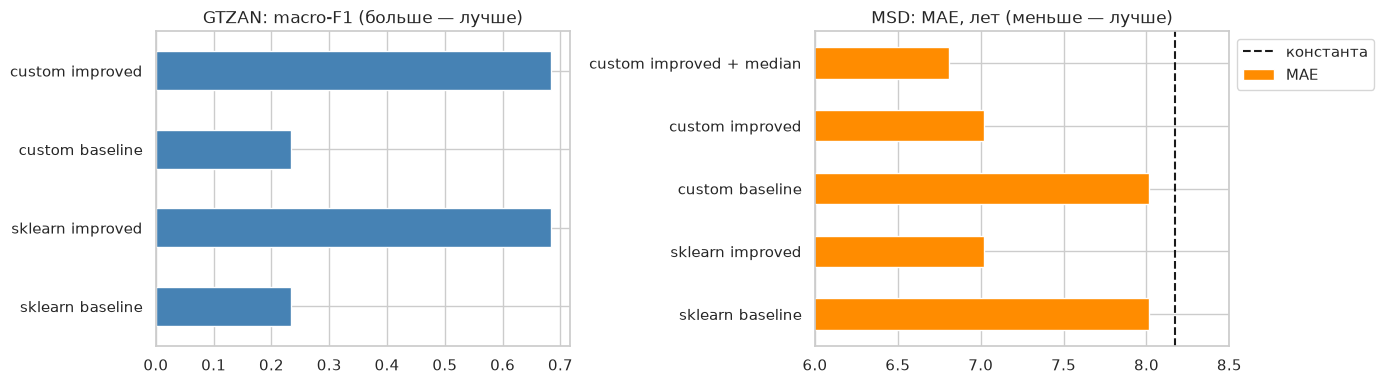

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
res_c["f1_macro"].plot.barh(ax=axes[0], color="steelblue"); axes[0].set_title("GTZAN: macro-F1 (больше — лучше)")
res_r["MAE"].plot.barh(ax=axes[1], color="darkorange"); axes[1].set_title("MSD: MAE, лет (меньше — лучше)")
axes[1].axvline(regression_metrics(yr_test, dummy_r.predict(Xr_test))["MAE"], color="k", ls="--", label="константа")
axes[1].set_xlim(6, 8.5)
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

### Выводы по лабораторной работе

1. **Данные и постановка.** Выбраны две музыкальные задачи: определение жанра по аудиопризнакам (GTZAN) и
   предсказание года выпуска по тембру (YearPredictionMSD). Для обеих важно правильно разбить данные:
   в GTZAN фрагменты одного трека нельзя разносить по train и test, иначе оценка завышается примерно на 23 п.п.,
   в MSD используется официальное разбиение по исполнителям.
2. **Бейзлайн** KNN «из коробки» на сырых признаках работает плохо: в регрессии он хуже константы, в классификации
   ненамного лучше случайного угадывания. Причина — разные масштабы признаков.
3. **Улучшение бейзлайна.** Ключевые факторы:
   * масштабирование признаков — главный источник прироста;
   * правильный выбор метрики расстояния: манхэттенская для GTZAN, косинусная для MSD;
   * подбор k и взвешивание соседей по расстоянию: нужно в несколько раз больше соседей, чем по умолчанию (k = 5).

   В GTZAN дополнительно помогает квантильное преобразование тяжелохвостых признаков к нормальному виду. В MSD
   оно не помогает. PCA и отбор признаков не помогли ни в одной задаче.
4. **Собственная реализация** (векторизованный полный перебор на NumPy) совпадает с sklearn по предсказаниям и
   метрикам как в условиях бейзлайна, так и с улучшениями. Своя реализация позволила проверить идею, которой
   нет в sklearn: медиана соседей вместо среднего дополнительно снижает MAE ценой роста RMSE.
5. **Ограничения KNN** на этих данных: в регрессии прогнозы стягиваются к центру распределения года, а в
   классификации путаются близкие по звучанию жанры (rock, country, disco). Эти результаты — точка отсчёта для
   линейных моделей, деревьев и ансамблей в ЛР 2–5.